Age pyramid - unweighted - useless

MATSim: 34461 persons, 34461 with valid age and sex
Mikrozensus read with encoding: cp1252
Mikrozensus: 57090 persons, 57090 with valid age and sex


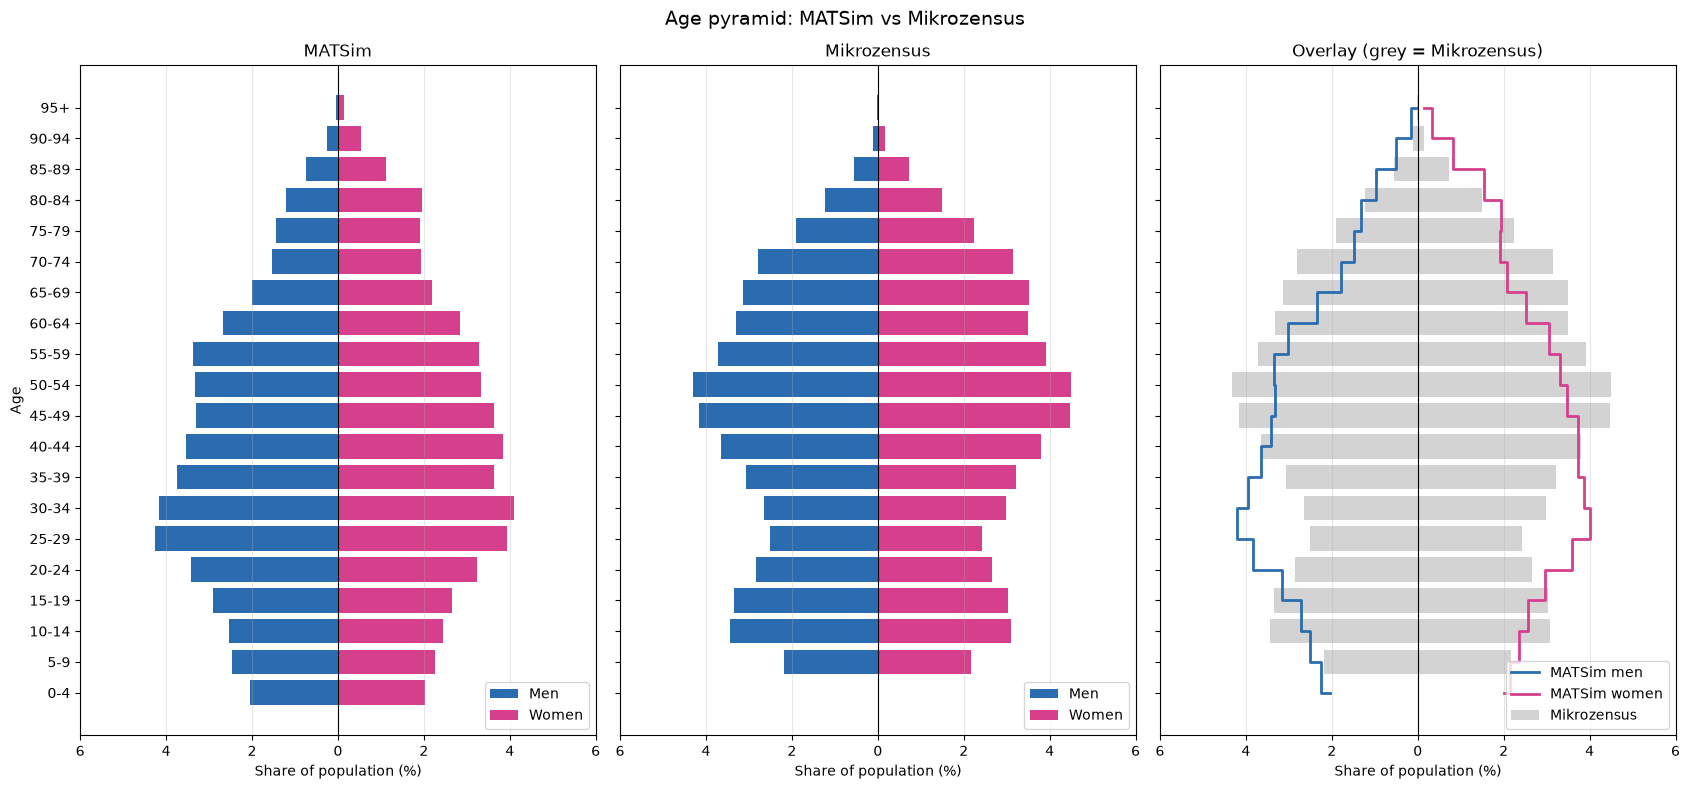

Saved to C:\Users\Sylvain\Documents\GitHub\abmt-2026\ass_2\working_rep\validation


In [ ]:
""" Age pyramid: MATSim population vs Mikrozensus (zielpersonen.csv)
Run from the folder that contains Lausanne_10pct (adjust paths below if needed).
unweighted
"""
import gzip
from pathlib import Path
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------------ paths
MATSIM_PATH = Path(r"working_rep\filterred_data\lausanne_population_filtered.xml.gz")
MZ_PATH = Path("Lausanne_10pct/Lausanne_10pct/Mikrozensus/microcensus/zielpersonen.csv")
OUT_DIR = Path("working_rep/validation")
OUT_DIR.mkdir(parents=True, exist_ok=True)

BIN_WIDTH = 5
MAX_AGE = 100
BINS = list(range(0, MAX_AGE + BIN_WIDTH, BIN_WIDTH))
LABELS = [f"{a}-{a + BIN_WIDTH - 1}" for a in BINS[:-2]] + [f"{BINS[-2]}+"]


# ------------------------------------------------------------------ MATSim
def read_matsim(path):
    """Returns DataFrame with columns age, sex ('m'/'f'). Handles attribute-style
    (<attributes><attribute name="age">) and old-style (<person age= sex=>) files."""
    rows = []
    person = None
    in_plan = False
    with gzip.open(path, "rb") as f:
        for event, elem in ET.iterparse(f, events=("start", "end")):
            tag = elem.tag
            if event == "start":
                if tag == "person":
                    person = {"age": elem.get("age"), "sex": elem.get("sex")}
                elif tag == "plan":
                    in_plan = True
            else:
                if tag == "attribute" and person is not None and not in_plan:
                    name = elem.get("name")
                    if name in ("age", "sex", "gender"):
                        person["sex" if name == "gender" else name] = (elem.text or "").strip()
                elif tag == "plan":
                    in_plan = False
                    elem.clear()
                elif tag == "person":
                    rows.append(person)
                    person = None
                    elem.clear()
    df = pd.DataFrame(rows)
    df["age"] = pd.to_numeric(df["age"], errors="coerce")
    df["sex"] = df["sex"].astype(str).str.lower().str[0].map({"m": "m", "f": "f"})
    n0 = len(df)
    df = df.dropna(subset=["age", "sex"])
    print(f"MATSim: {n0} persons, {len(df)} with valid age and sex")
    return df


# ------------------------------------------------------------------ Mikrozensus
def read_mz(path):
    for enc in ("utf-8", "cp1252", "latin-1"):
        try:
            df = pd.read_csv(path, sep=None, engine="python",
                             usecols=["alter", "gesl"], encoding=enc)
            print(f"Mikrozensus read with encoding: {enc}")
            break
        except UnicodeDecodeError:
            continue
    df["age"] = pd.to_numeric(df["alter"], errors="coerce")
    df["sex"] = df["gesl"].map({1: "m", 2: "f"})
    n0 = len(df)
    df = df[df["age"] >= 0].dropna(subset=["age", "sex"])  # drop negative missing codes
    print(f"Mikrozensus: {n0} persons, {len(df)} with valid age and sex")
    return df[["age", "sex"]]


# ------------------------------------------------------------------ helpers
def shares(df):
    """% of total population per age bin and sex."""
    ages = df["age"].clip(upper=MAX_AGE)
    cut = pd.cut(ages, bins=BINS, right=False, labels=LABELS)
    tab = pd.crosstab(cut, df["sex"]).reindex(LABELS, fill_value=0)
    for s in ("m", "f"):
        if s not in tab:
            tab[s] = 0
    return tab[["m", "f"]] / len(df) * 100


def plot(mat, mz):
    y = np.arange(len(LABELS))
    xmax = max(mat.values.max(), mz.values.max()) * 1.1
    fig, axes = plt.subplots(1, 3, figsize=(17, 8), sharey=True)

    for ax, tab, title in [(axes[0], mat, "MATSim"), (axes[1], mz, "Mikrozensus")]:
        ax.barh(y, -tab["m"], color="#2b6cb0", label="Men")
        ax.barh(y, tab["f"], color="#d53f8c", label="Women")
        ax.set_title(title)

    # overlay comparison
    ax = axes[2]
    ax.barh(y, -mz["m"], color="lightgrey", label="Mikrozensus")
    ax.barh(y, mz["f"], color="lightgrey")
    ax.step(-mat["m"], y, where="mid", color="#2b6cb0", lw=2, label="MATSim men")
    ax.step(mat["f"], y, where="mid", color="#d53f8c", lw=2, label="MATSim women")
    ax.set_title("Overlay (grey = Mikrozensus)")

    for ax in axes:
        ax.set_xlim(-xmax, xmax)
        ax.set_yticks(y)
        ax.set_yticklabels(LABELS)
        ax.set_xticks(ax.get_xticks())
        ax.set_xticklabels([f"{abs(t):.0f}" for t in ax.get_xticks()])
        ax.set_xlabel("Share of population (%)")
        ax.axvline(0, color="black", lw=0.8)
        ax.grid(axis="x", alpha=0.3)
        ax.legend(loc="lower right")
    axes[0].set_ylabel("Age")
    fig.suptitle("Age pyramid: MATSim vs Mikrozensus", fontsize=14)
    fig.tight_layout()
    fig.savefig(OUT_DIR / "age_pyramid_uw.png", dpi=200)
    plt.show()


# ------------------------------------------------------------------ main
if __name__ == "__main__":
    matsim = read_matsim(MATSIM_PATH)
    mz = read_mz(MZ_PATH)

    s_mat, s_mz = shares(matsim), shares(mz)

    out = pd.concat({"matsim_%": s_mat, "mikrozensus_%": s_mz}, axis=1)
    out.columns = [f"{a}_{b}" for a, b in out.columns]
    out["diff_m"] = out["matsim_%_m"] - out["mikrozensus_%_m"]
    out["diff_f"] = out["matsim_%_f"] - out["mikrozensus_%_f"]
    out.round(3).to_csv(OUT_DIR / "age_pyramid_table.csv")

    plot(s_mat, s_mz)
    print(f"Saved to {OUT_DIR.resolve()}")

Age pyramid - weighted - min age 6

MATSim: 34461 persons, 34461 with valid age and sex
Mikrozensus read with encoding: cp1252
Household filter: 57090 -> 1943 persons (1943 households)
Mikrozensus: 1943 persons, 1943 with valid age and sex


C:\Users\Sylvain\AppData\Local\Temp\ipykernel_5784\2911803340.py:137: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["age"] = pd.to_numeric(df["alter"], errors="coerce")
C:\Users\Sylvain\AppData\Local\Temp\ipykernel_5784\2911803340.py:138: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["sex"] = df["gesl"].map({1: "m", 2: "f"})
C:\Users\Sylvain\AppData\Local\Temp\ipykernel_5784\2911803340.py:140: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poo

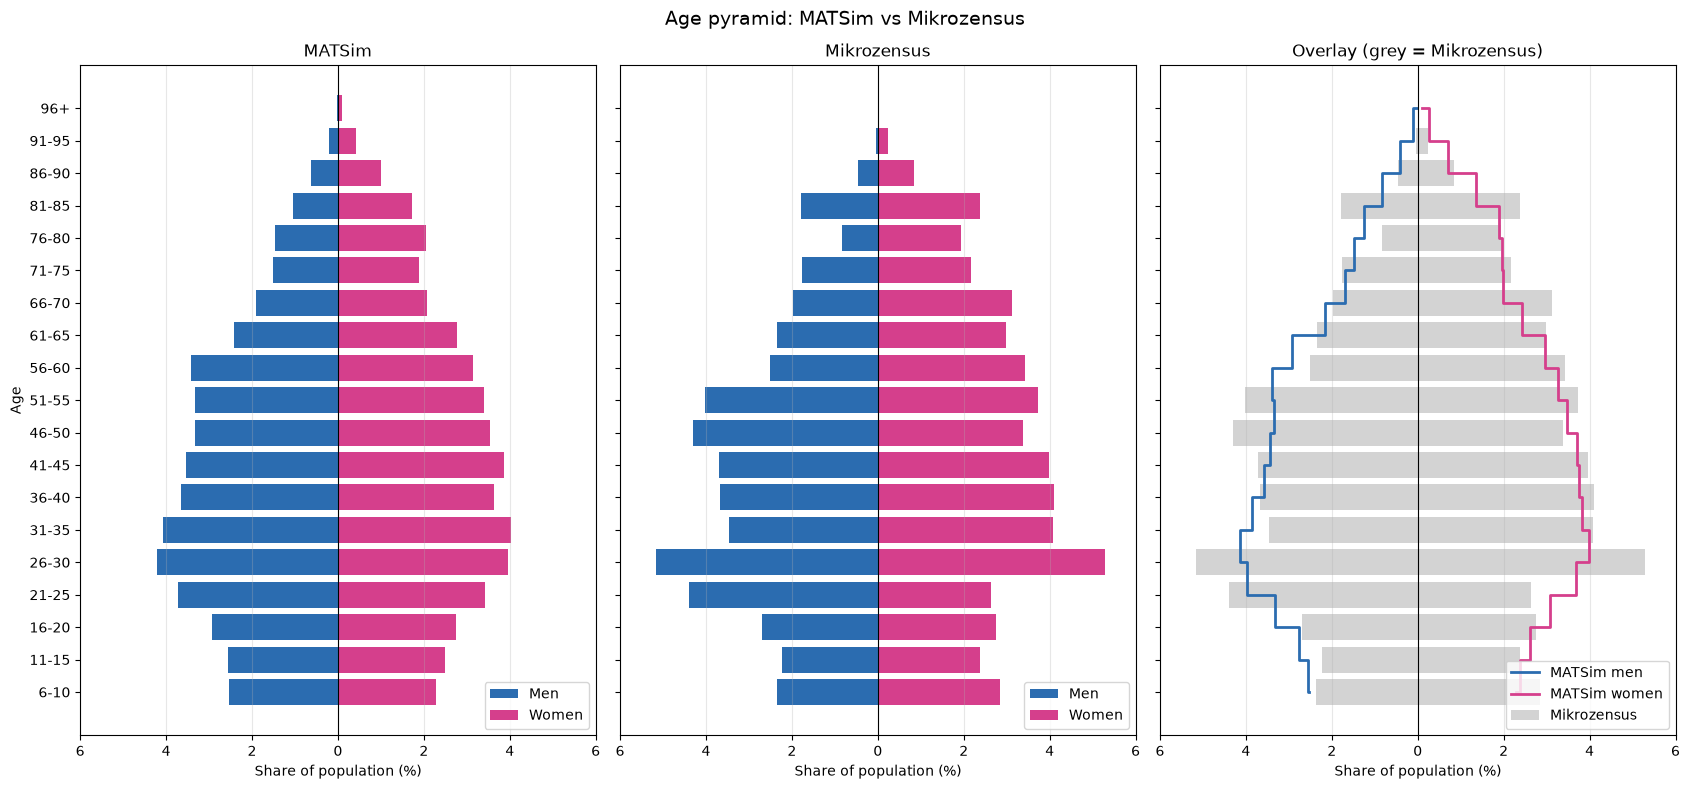

Saved to C:\Users\Sylvain\Documents\GitHub\abmt-2026\ass_2\working_rep\validation


In [3]:
"""
Age pyramid: MATSim population vs Mikrozensus (zielpersonen.csv)

Purpose
-------
Validates the synthetic MATSim population against the Swiss Mikrozensus
(microcensus) by comparing their age/sex distributions.

Workflow
--------
1. Read the MATSim population (gzipped XML) -> age + sex per person.
2. Read the Mikrozensus target persons, keep only households located in the
   study area, and keep the survey weights (WP).
3. Compute the share (%) of the total population in each 5-year age bin,
   separately for men and women. MATSim is unweighted, Mikrozensus is weighted.
4. Save a comparison table (CSV) and a 3-panel pyramid plot (PNG):
   MATSim | Mikrozensus | overlay.

Run from the folder that contains Lausanne_10pct (adjust paths below if needed).
"""
import gzip
from pathlib import Path
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------------ paths
# Input: filtered MATSim population (gzipped XML)
MATSIM_PATH = Path(r"working_rep\filterred_data\lausanne_population_filtered.xml.gz")
# Input: Mikrozensus target-person file (one row per surveyed person)
MZ_PATH = Path("Lausanne_10pct/Lausanne_10pct/Mikrozensus/microcensus/zielpersonen.csv")
# Output folder for the table and the figure (created if missing)
OUT_DIR = Path("working_rep/validation")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Age binning: 5-year classes from 0 to 100, last class is open-ended ("100+")
MIN_AGE = 6       # minimum age of persons to include (set to 0 to keep everyone)
BIN_WIDTH = 5
MAX_AGE = 100     # the open-ended last bin starts at the last edge <= MAX_AGE
# Bin edges start at MIN_AGE, e.g. 6, 11, 16, ..., 96, then infinity to close the
# open-ended last bin (with MIN_AGE = 0 this gives 0, 5, ..., 100, inf).
BINS = list(range(MIN_AGE, MAX_AGE + 1, BIN_WIDTH)) + [np.inf]
# Labels like "6-10", "11-15", ... for all bins but the last, plus "96+"
# (or "100+" when MIN_AGE = 0) for the open-ended final bin.
LABELS = [f"{a}-{a + BIN_WIDTH - 1}" for a in BINS[:-2]] + [f"{BINS[-2]}+"]


# ------------------------------------------------------------------ MATSim
def read_matsim(path):
    """Returns DataFrame with columns age, sex ('m'/'f'). Handles attribute-style
    (<attributes><attribute name="age">) and old-style (<person age= sex=>) files."""
    rows = []          # one dict (age, sex) per person
    person = None      # the person currently being parsed
    in_plan = False    # True while inside a <plan>; used to ignore plan-level attributes

    # Stream-parse the file (iterparse) so large populations don't need to fit in memory
    with gzip.open(path, "rb") as f:
        for event, elem in ET.iterparse(f, events=("start", "end")):
            tag = elem.tag
            if event == "start":
                if tag == "person":
                    # Old-style format: age/sex are XML attributes of <person>.
                    # (They are None for the new attribute-style format.)
                    person = {"age": elem.get("age"), "sex": elem.get("sex")}
                elif tag == "plan":
                    in_plan = True
            else:  # event == "end": the element and its children are fully parsed
                if tag == "attribute" and person is not None and not in_plan:
                    # New-style format: <attribute name="age">42</attribute>
                    # Only person-level attributes are read (not those inside plans).
                    name = elem.get("name")
                    if name in ("age", "sex", "gender"):
                        # "gender" is treated as an alias for "sex"
                        person["sex" if name == "gender" else name] = (elem.text or "").strip()
                elif tag == "plan":
                    in_plan = False
                    elem.clear()   # free memory: plans are large and not needed
                elif tag == "person":
                    rows.append(person)
                    person = None
                    elem.clear()   # free memory

    df = pd.DataFrame(rows)
    # Convert age to a number; unparseable values become NaN
    df["age"] = pd.to_numeric(df["age"], errors="coerce")
    # Normalise sex to 'm'/'f' using the first letter (handles "male", "Female", "M", ...);
    # anything else becomes NaN
    df["sex"] = df["sex"].astype(str).str.lower().str[0].map({"m": "m", "f": "f"})
    n0 = len(df)
    # Drop persons without a valid age or sex
    df = df.dropna(subset=["age", "sex"])
    print(f"MATSim: {n0} persons, {len(df)} with valid age and sex")
    return df


# ------------------------------------------------------------------ Mikrozensus
def read_mz(path):
    """Reads the Mikrozensus person file, restricts it to households in the study
    area, and returns a DataFrame with columns age, sex ('m'/'f') and weight."""
    # Try several encodings, since the file may not be UTF-8 (typical for Swiss
    # data exports). sep=None with the python engine lets pandas auto-detect the
    # delimiter (comma, semicolon, tab, ...).
    # NOTE: if all three encodings fail, `df` is never defined; latin-1 can decode
    # any byte sequence, so in practice the last attempt always succeeds.
    for enc in ("utf-8", "cp1252", "latin-1"):
        try:
            df = pd.read_csv(
                path,
                sep=None,
                engine="python",
                encoding=enc
            )
            print(f"Mikrozensus read with encoding: {enc}")
            break
        except UnicodeDecodeError:
            continue

    # -------------------------------------------------- filter households
    # Keep only persons whose household (HHNR) lies inside the study area.
    # The list of household IDs was produced in an earlier filtering step.
    hh_file = Path(r"working_rep/filterred_data/mz/household_ids_in_area.csv")

    hh_ids = pd.read_csv(hh_file)["HHNR"].unique()

    n_before = len(df)
    df = df[df["HHNR"].isin(hh_ids)]
    print(
        f"Household filter: {n_before} -> {len(df)} persons "
        f"({df['HHNR'].nunique()} households)"
    )

    # -------------------------------------------------- age / sex
    # Column names follow the Mikrozensus codebook:
    #   alter = age in years, gesl = sex (1 = male, 2 = female), WP = person weight
    df["age"] = pd.to_numeric(df["alter"], errors="coerce")
    df["sex"] = df["gesl"].map({1: "m", 2: "f"})
    # Missing weights are set to 0 so those persons don't contribute to the totals
    df["weight"] = pd.to_numeric(df["WP"], errors="coerce").fillna(0)

    n0 = len(df)
    # Remove invalid ages (negative values are typically "no answer" codes)
    # and rows with missing age or sex
    df = df[df["age"] >= 0].dropna(subset=["age", "sex"])

    print(f"Mikrozensus: {n0} persons, {len(df)} with valid age and sex")

    return df[["age", "sex", "weight"]]


# ------------------------------------------------------------------ helpers
def shares(df, weight_col=None):
    """% of total population per age bin and sex.

    Returns a DataFrame indexed by age-bin label with columns 'm' and 'f'.
    Values are percentages of the *total* population (men + women), so the
    sum over all cells equals 100. If weight_col is given, the weights are
    summed instead of counting persons."""

    # Ages above MAX_AGE are put into the last open-ended bin ("100+")
    ages = df["age"].clip(upper=MAX_AGE)
    # right=False -> bins are [0,5), [5,10), ... (left-inclusive)
    bins = pd.cut(ages, bins=BINS, right=False, labels=LABELS)

    if weight_col is None:
        # Unweighted: simple head count per (age bin, sex)
        tab = pd.crosstab(bins, df["sex"])
        total = len(df)
    else:
        # Weighted: sum of survey weights per (age bin, sex)
        tmp = pd.DataFrame({
            "age_bin": bins,
            "sex": df["sex"],
            "weight": df[weight_col]
        })

        tab = pd.pivot_table(
            tmp,
            index="age_bin",
            columns="sex",
            values="weight",
            aggfunc="sum",
            fill_value=0,
            observed=False,   # keep empty bins as well
        )

        total = tmp["weight"].sum()

    # Make sure all age bins are present and in the right order
    tab = tab.reindex(LABELS, fill_value=0)

    # Guard against a sex being completely absent from the data
    for s in ("m", "f"):
        if s not in tab:
            tab[s] = 0

    # Convert counts/weights to percentages of the total population
    return tab[["m", "f"]] / total * 100


def plot(mat, mz):
    """Draws three side-by-side panels sharing the same age axis:
    (1) MATSim pyramid, (2) Mikrozensus pyramid, (3) overlay of both."""
    y = np.arange(len(LABELS))  # one y position per age bin
    # Common x-limit (+10% margin) so all panels are directly comparable
    xmax = max(mat.values.max(), mz.values.max()) * 1.1
    fig, axes = plt.subplots(1, 3, figsize=(17, 8), sharey=True)

    # Panels 1 and 2: classic pyramids. Men are plotted as negative values
    # (extending left), women as positive values (extending right).
    for ax, tab, title in [(axes[0], mat, "MATSim"), (axes[1], mz, "Mikrozensus")]:
        ax.barh(y, -tab["m"], color="#2b6cb0", label="Men")
        ax.barh(y, tab["f"], color="#d53f8c", label="Women")
        ax.set_title(title)

    # Panel 3 - overlay: Mikrozensus as grey bars (reference),
    # MATSim as coloured step lines on top, so deviations are easy to spot
    ax = axes[2]
    ax.barh(y, -mz["m"], color="lightgrey", label="Mikrozensus")
    ax.barh(y, mz["f"], color="lightgrey")
    ax.step(-mat["m"], y, where="mid", color="#2b6cb0", lw=2, label="MATSim men")
    ax.step(mat["f"], y, where="mid", color="#d53f8c", lw=2, label="MATSim women")
    ax.set_title("Overlay (grey = Mikrozensus)")

    # Formatting shared by all three panels
    for ax in axes:
        ax.set_xlim(-xmax, xmax)
        ax.set_yticks(y)
        ax.set_yticklabels(LABELS)
        # Fix the tick positions, then relabel them with absolute values
        # (the left side is stored as negative numbers but should read as positive %)
        ax.set_xticks(ax.get_xticks())
        ax.set_xticklabels([f"{abs(t):.0f}" for t in ax.get_xticks()])
        ax.set_xlabel("Share of population (%)")
        ax.axvline(0, color="black", lw=0.8)  # centre line between men and women
        ax.grid(axis="x", alpha=0.3)
        ax.legend(loc="lower right")
    axes[0].set_ylabel("Age")
    fig.suptitle("Age pyramid: MATSim vs Mikrozensus", fontsize=14)
    fig.tight_layout()
    fig.savefig(OUT_DIR / "age_pyramid_w.png", dpi=200)
    plt.show()


# ------------------------------------------------------------------ main
if __name__ == "__main__":
    matsim = read_matsim(MATSIM_PATH)
    mz = read_mz(MZ_PATH)

    s_mat = shares(matsim)                 # unweighted MATSim (each agent counts as 1)
    s_mz  = shares(mz, weight_col="weight")  # weighted Mikrozensus (survey weights WP)

    # Build a comparison table: one column per (source, sex), e.g. matsim_%_m
    out = pd.concat({"matsim_%": s_mat, "mikrozensus_%": s_mz}, axis=1)
    out.columns = [f"{a}_{b}" for a, b in out.columns]  # flatten the MultiIndex
    # Differences in percentage points (positive = MATSim over-represents the group)
    out["diff_m"] = out["matsim_%_m"] - out["mikrozensus_%_m"]
    out["diff_f"] = out["matsim_%_f"] - out["mikrozensus_%_f"]
    out.round(3).to_csv(OUT_DIR / "age_pyramid_table.csv")

    plot(s_mat, s_mz)
    print(f"Saved to {OUT_DIR.resolve()}")

Age distribution representation bins = 1 year

MATSim: 34461 persons, 34461 with valid age
Mikrozensus read with encoding: cp1252
Mikrozensus: 1943 persons, 1943 with valid age
Age axis: 6 to 103 (98 bins)


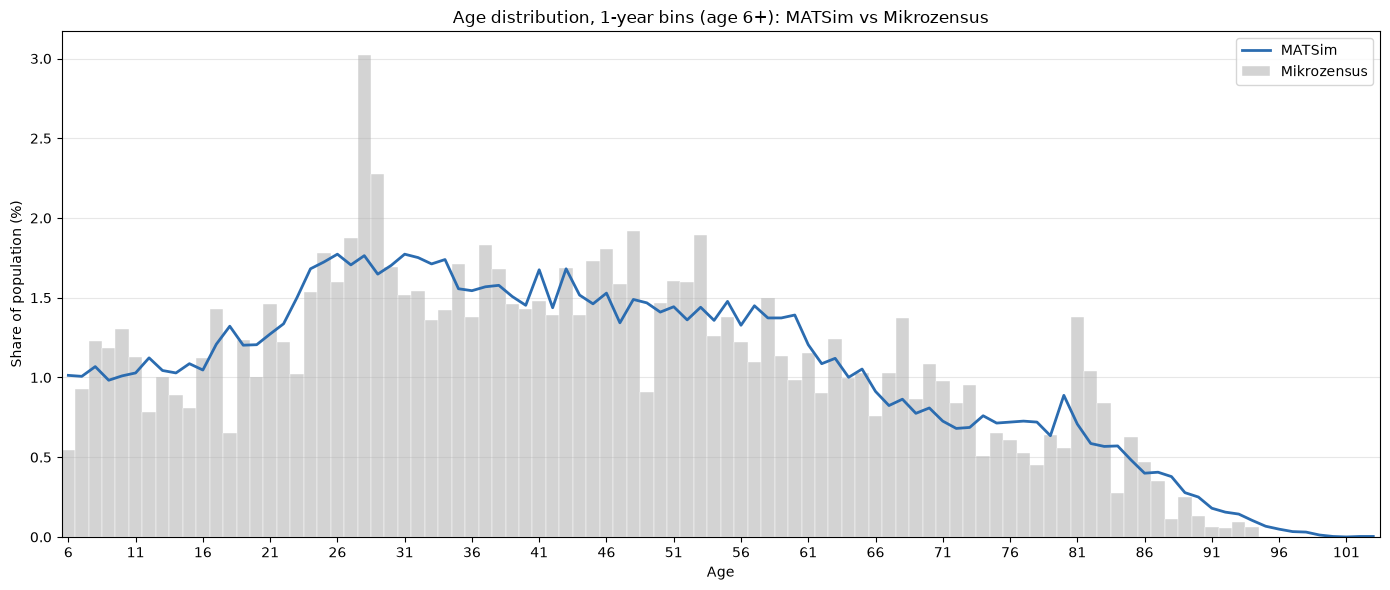

Saved to C:\Users\Sylvain\Documents\GitHub\abmt-2026\ass_2\working_rep\validation


In [10]:
"""
Age distribution (1-year bins, from MIN_AGE to the maximum age found):
Mikrozensus (weighted) as full bars, MATSim (unweighted) as a curve on top.

Uses the same inputs and the same reading logic as the age pyramid script.
Shares are % of all persons aged >= MIN_AGE (men + women), so each source sums to 100.
"""
import gzip
from pathlib import Path
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------------ paths
MATSIM_PATH = Path(r"working_rep\filterred_data\lausanne_population_filtered.xml.gz")
MZ_PATH = Path("Lausanne_10pct/Lausanne_10pct/Mikrozensus/microcensus/zielpersonen.csv")
HH_FILE = Path(r"working_rep/filterred_data/mz/household_ids_in_area.csv")
OUT_DIR = Path("working_rep/validation")
OUT_DIR.mkdir(parents=True, exist_ok=True)

MIN_AGE = 6
HORIZONTAL = False  # True: age on the y-axis, horizontal bars, curve to the right of them
                    # False: age on the x-axis, vertical bars, curve above them


# ------------------------------------------------------------------ MATSim
def read_matsim(path):
    rows, person, in_plan = [], None, False
    with gzip.open(path, "rb") as f:
        for event, elem in ET.iterparse(f, events=("start", "end")):
            tag = elem.tag
            if event == "start":
                if tag == "person":
                    person = {"age": elem.get("age")}
                elif tag == "plan":
                    in_plan = True
            else:
                if tag == "attribute" and person is not None and not in_plan:
                    if elem.get("name") == "age":
                        person["age"] = (elem.text or "").strip()
                elif tag == "plan":
                    in_plan = False
                    elem.clear()
                elif tag == "person":
                    rows.append(person)
                    person = None
                    elem.clear()
    df = pd.DataFrame(rows)
    df["age"] = pd.to_numeric(df["age"], errors="coerce")
    n0 = len(df)
    df = df.dropna(subset=["age"])
    print(f"MATSim: {n0} persons, {len(df)} with valid age")
    return df


# ------------------------------------------------------------------ Mikrozensus
def read_mz(path):
    for enc in ("utf-8", "cp1252", "latin-1"):
        try:
            df = pd.read_csv(path, sep=None, engine="python", encoding=enc)
            print(f"Mikrozensus read with encoding: {enc}")
            break
        except UnicodeDecodeError:
            continue

    hh_ids = pd.read_csv(HH_FILE)["HHNR"].unique()
    df = df[df["HHNR"].isin(hh_ids)].copy()

    df["age"] = pd.to_numeric(df["alter"], errors="coerce")
    df["weight"] = pd.to_numeric(df["WP"], errors="coerce").fillna(0)
    n0 = len(df)
    df = df[df["age"] >= 0].dropna(subset=["age"])
    print(f"Mikrozensus: {n0} persons, {len(df)} with valid age")
    return df[["age", "weight"]]


# ------------------------------------------------------------------ helpers
def shares_1y(ages, ages_axis, weights=None):
    """% of persons per single year of age (floor of age), on a fixed age axis."""
    a = np.floor(ages).astype(int)
    w = np.ones(len(a)) if weights is None else np.asarray(weights, dtype=float)
    s = pd.Series(w, index=a).groupby(level=0).sum()
    s = s.reindex(ages_axis, fill_value=0)
    return s / s.sum() * 100


def plot(ages_axis, mz_share, mat_share):
    fig, ax = plt.subplots(figsize=(8, 12) if HORIZONTAL else (14, 6))

    if HORIZONTAL:
        ax.barh(ages_axis, mz_share.values, height=1.0, color="lightgrey",
                edgecolor="white", linewidth=0.3, label="Mikrozensus")
        ax.plot(mat_share.values, ages_axis, color="#2b6cb0", lw=2, label="MATSim")
        ax.set_xlabel("Share of population (%)")
        ax.set_ylabel("Age")
        ax.set_ylim(ages_axis[0] - 0.5, ages_axis[-1] + 0.5)
        ax.set_yticks(range(ages_axis[0], ages_axis[-1] + 1, 5))
        ax.grid(axis="x", alpha=0.3)
    else:
        ax.bar(ages_axis, mz_share.values, width=1.0, color="lightgrey",
               edgecolor="white", linewidth=0.3, label="Mikrozensus")
        ax.plot(ages_axis, mat_share.values, color="#2b6cb0", lw=2, label="MATSim")
        ax.set_xlabel("Age")
        ax.set_ylabel("Share of population (%)")
        ax.set_xlim(ages_axis[0] - 0.5, ages_axis[-1] + 0.5)
        ax.set_xticks(range(ages_axis[0], ages_axis[-1] + 1, 5))
        ax.grid(axis="y", alpha=0.3)

    ax.legend()
    ax.set_title(f"Age distribution, 1-year bins (age {ages_axis[0]}+): MATSim vs Mikrozensus")
    fig.tight_layout()
    fig.savefig(OUT_DIR / "age_distribution_1y.png", dpi=200)
    plt.show()


# ------------------------------------------------------------------ main
if __name__ == "__main__":
    matsim = read_matsim(MATSIM_PATH)
    mz = read_mz(MZ_PATH)

    matsim = matsim[matsim["age"] >= MIN_AGE]
    mz = mz[mz["age"] >= MIN_AGE]

    max_age = int(np.floor(max(matsim["age"].max(), mz["age"].max())))
    ages_axis = list(range(MIN_AGE, max_age + 1))
    print(f"Age axis: {MIN_AGE} to {max_age} ({len(ages_axis)} bins)")

    s_mat = shares_1y(matsim["age"], ages_axis)
    s_mz = shares_1y(mz["age"], ages_axis, weights=mz["weight"])

    out = pd.DataFrame({"matsim_%": s_mat, "mikrozensus_%": s_mz})
    out["diff"] = out["matsim_%"] - out["mikrozensus_%"]
    out.index.name = "age"
    out.round(4).to_csv(OUT_DIR / "age_distribution_1y_table.csv")

    plot(ages_axis, s_mz, s_mat)
    print(f"Saved to {OUT_DIR.resolve()}")

Driving licence comparaison


MATSim: 34,461 persons with licence info, 32,766 aged >= 6

MZ household filter: 57,090 -> 1,943 persons
MZ: 1,943 persons -> 1,943 with licence info and aged >= 6

MATSim %
hasLicense
yes    70.353415
no     29.646585
Name: weight, dtype: float64

Mikrozensus weighted %
hasLicense
yes    67.925107
no     32.074893
Name: weight, dtype: float64


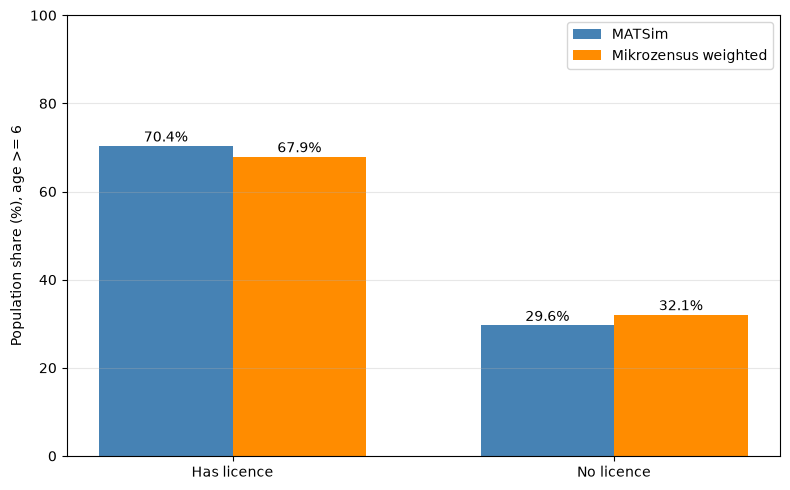

In [8]:
"""
Driving-licence validation: MATSim synthetic population vs. Mikrozensus (MZ).

Compares the share of persons with / without a driving licence in the
MATSim population and in the (weighted) Mikrozensus, restricted to
persons aged MIN_AGE and above.
"""

import gzip
from pathlib import Path
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------------ settings

MATSIM_PATH = Path("working_rep/filterred_data/lausanne_population_filtered.xml.gz")
MZ_PATH = Path(r"Lausanne_10pct\Lausanne_10pct\Mikrozensus\microcensus\zielpersonen.csv")
HH_PATH = Path("working_rep/filterred_data/mz/household_ids_in_area.csv")  # households inside study area

OUT_DIR = Path("working_rep/validation")
OUT_DIR.mkdir(parents=True, exist_ok=True)

MIN_AGE = 6  # only persons of this age or older are considered
CATEGORIES = ["yes", "no"]  # order used for shares and plot


# ------------------------------------------------------------------ MATSim

def read_matsim(path):
    """Read the MATSim population (gzipped XML).

    Returns a DataFrame with columns: age, hasLicense ('yes'/'no'), weight (=1).
    Only person-level attributes are read; attributes inside <plan> are ignored.
    """
    rows = []          # one dict per person
    person = None      # person currently being parsed
    in_plan = False    # True while inside a <plan> (plan attributes are skipped)

    # Stream-parse so large populations don't have to fit in memory
    with gzip.open(path, "rb") as f:
        for event, elem in ET.iterparse(f, events=("start", "end")):
            tag = elem.tag

            if event == "start":
                if tag == "person":
                    # Old-style files store age as an XML attribute of <person>
                    # (None for attribute-style files, overwritten below)
                    person = {"age": elem.get("age")}
                elif tag == "plan":
                    in_plan = True

            else:  # "end": element and its children are fully parsed
                if tag == "attribute" and person is not None and not in_plan:
                    # New-style files: <attribute name="age">42</attribute>
                    name = elem.get("name")
                    if name in ("age", "hasLicense"):
                        person[name] = (elem.text or "").strip().lower()
                elif tag == "plan":
                    in_plan = False
                elif tag == "person":
                    # Keep only persons for which a licence status is known
                    if "hasLicense" in person:
                        rows.append(person)
                    person = None
                    elem.clear()  # free memory

    df = pd.DataFrame(rows)
    df["age"] = pd.to_numeric(df["age"], errors="coerce")  # invalid -> NaN
    df["weight"] = 1.0                                     # every agent counts once

    n0 = len(df)
    df = df[df["age"] >= MIN_AGE]  # also drops NaN ages (comparison is False)
    print(f"\nMATSim: {n0:,} persons with licence info, {len(df):,} aged >= {MIN_AGE}")

    return df


# ------------------------------------------------------------------ Mikrozensus

def read_mz(path):
    """Read the MZ person file, keep persons in the study area aged >= MIN_AGE.

    Returns a DataFrame with columns: age, hasLicense ('yes'/'no'), weight.
    Codebook: alter = age, f20400a = licence (1 = yes, 2 = no), WP = person weight.
    """
    # Swiss exports are often not UTF-8, so try several encodings.
    # sep=None lets pandas auto-detect the delimiter. latin-1 decodes any bytes,
    # so the last attempt always succeeds.
    for enc in ("utf-8", "cp1252", "latin-1"):
        try:
            df = pd.read_csv(path, sep=None, engine="python", encoding=enc)
            break
        except UnicodeDecodeError:
            continue

    # Keep only households inside the study area
    hh_ids = pd.read_csv(HH_PATH)["HHNR"].unique()
    n0 = len(df)
    df = df[df["HHNR"].isin(hh_ids)].copy()
    print(f"\nMZ household filter: {n0:,} -> {len(df):,} persons")

    # Convert codes to usable values (invalid entries become NaN)
    df["age"] = pd.to_numeric(df["alter"], errors="coerce")
    df["hasLicense"] = pd.to_numeric(df["f20400a"], errors="coerce").map({1: "yes", 2: "no", -99: "no"})
    df["weight"] = pd.to_numeric(df["WP"], errors="coerce").fillna(0)  # missing weight -> no contribution

    # Drop unknown licence status and apply the age filter (also removes NaN / negative ages)
    n0 = len(df)
    df = df.dropna(subset=["hasLicense"])
    df = df[df["age"] >= MIN_AGE]
    print(f"MZ: {n0:,} persons -> {len(df):,} with licence info and aged >= {MIN_AGE}")

    return df[["age", "hasLicense", "weight"]]


# ------------------------------------------------------------------ shares

def licence_share(df):
    """Weighted share (%) of 'yes' / 'no'. MATSim has weight 1, so it is a plain count."""
    totals = df.groupby("hasLicense")["weight"].sum().reindex(CATEGORIES, fill_value=0)
    return totals / totals.sum() * 100


# ------------------------------------------------------------------ plot

def plot(matsim_share, mz_share):
    """Grouped bar chart of MATSim vs. weighted MZ shares, saved to OUT_DIR."""
    labels = ["Has licence", "No licence"]
    x = np.arange(len(labels))
    width = 0.35

    fig, ax = plt.subplots(figsize=(8, 5))

    # One bar group per source, offset left/right of each tick
    for offset, share, label, color in [
        (-width / 2, matsim_share, "MATSim", "steelblue"),
        (+width / 2, mz_share, "Mikrozensus weighted", "darkorange"),
    ]:
        values = share[CATEGORIES].values
        ax.bar(x + offset, values, width, label=label, color=color)
        for xi, v in zip(x + offset, values):
            ax.text(xi, v + 1, f"{v:.1f}%", ha="center")  # value label above bar

    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_ylabel(f"Population share (%), age >= {MIN_AGE}")
    ax.set_ylim(0, 100)
    ax.legend()
    ax.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.savefig(OUT_DIR / "driving_licence_validation.png", dpi=300)
    plt.show()


# ------------------------------------------------------------------ main

if __name__ == "__main__":
    matsim_share = licence_share(read_matsim(MATSIM_PATH))
    mz_share = licence_share(read_mz(MZ_PATH))

    print("\nMATSim %")
    print(matsim_share)
    print("\nMikrozensus weighted %")
    print(mz_share)

    plot(matsim_share, mz_share)

household municipality type comparaison

MATSim: 15987 households
MATSim municipalityType values found:
municipalityType
urban        7745
urbancore    7023
suburban     1219
Mikrozensus households read with encoding: cp1252
Household filter: 57090 -> 1943 households in the area
          matsim_n  mikrozensus_n_unweighted  matsim_%  mikrozensus_%  diff_pp
type                                                                          
urban        14768                      1348     92.38          73.99    18.38
suburban      1219                       489      7.62          22.20   -14.58
rural            0                       106      0.00           3.81    -3.81
unknown          0                         0      0.00           0.00     0.00


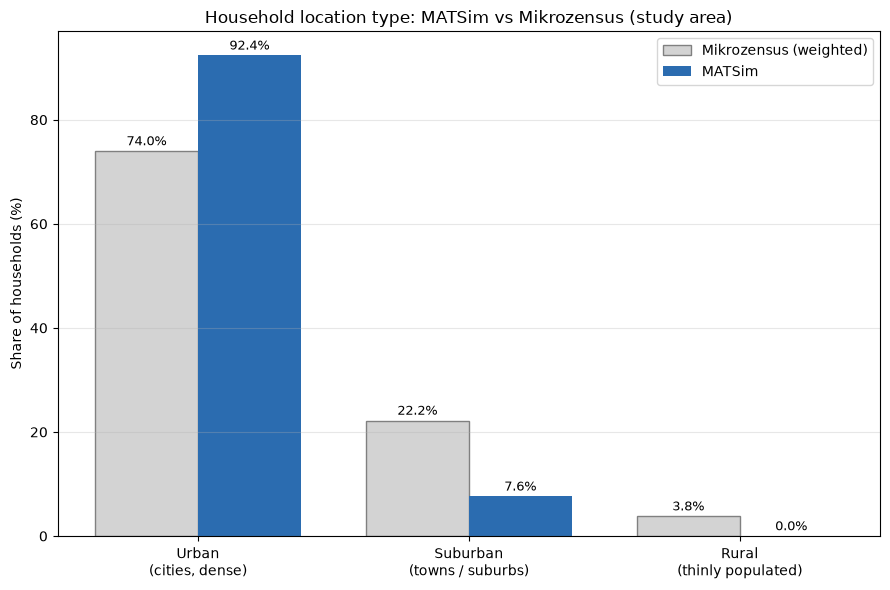

Saved to C:\Users\Sylvain\Documents\GitHub\abmt-2026\ass_2\working_rep\validation


In [15]:
"""
Household location type (urban / suburban / rural): MATSim vs Mikrozensus.

MATSim : lausanne_households_filtered.xml.gz -> <attribute name="municipalityType">
Mikrozensus: Haushalte.csv -> W_DEGURBA (DEGURBA classification),
             restricted to households in the study area (household_ids_in_area.csv),
             weighted by the household weight.

Shares are % of households (weighted for the Mikrozensus, unweighted for MATSim).
"""
import gzip
from pathlib import Path
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------------ paths
MATSIM_HH_PATH = Path(r"working_rep\filterred_data\lausanne_households_filtered.xml.gz")
MZ_HH_PATH = Path("Lausanne_10pct/Lausanne_10pct/Mikrozensus/microcensus/Haushalte.csv")
HH_FILE = Path(r"working_rep/filterred_data/mz/household_ids_in_area.csv")
OUT_DIR = Path("working_rep/validation")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Household weight column in Haushalte.csv. If it is not found, the script lists the
# available columns and falls back to unweighted counts (check the codebook!).
WEIGHT_COL = "WM"
EXCLUDE_UNKNOWN = False   # True: drop "unknown" households before computing shares

# ------------------------------------------------------------------ categories
CATS = ["urban", "suburban", "rural", "unknown"]
LABELS = {
    "urban": "Urban\n(cities, dense)",
    "suburban": "Suburban\n(towns / suburbs)",
    "rural": "Rural\n(thinly populated)",
    "unknown": "Unknown /\nmissing",
}
# Mikrozensus W_DEGURBA codes
MZ_MAP = {1: "urban", 2: "suburban", 3: "rural", -97: "unknown"}
# MATSim municipalityType strings (lower-cased); anything unlisted is reported and
# counted as "unknown" so nothing silently disappears.
MATSIM_MAP = {
    "urban": "urban", "urbancore": "urban", "cities": "urban",
    "suburban": "suburban", "intermediate": "suburban", "town": "suburban",
    "towns": "suburban", "semi-urban": "suburban", "semiurban": "suburban",
    "rural": "rural",
}



# ------------------------------------------------------------------ MATSim
def read_matsim_households(path):
    """One row per household with its municipalityType (raw string)."""
    rows, hh = [], None
    with gzip.open(path, "rb") as f:
        for event, elem in ET.iterparse(f, events=("start", "end")):
            # households files usually declare an XML namespace, which turns the tag
            # into "{http://...}household" -> strip it
            tag = elem.tag.rsplit("}", 1)[-1]
            if event == "start":
                if tag == "household":
                    hh = {"id": elem.get("id"), "municipalityType": None}
            else:
                if tag == "attribute" and hh is not None:
                    if elem.get("name") == "municipalityType":
                        hh["municipalityType"] = (elem.text or "").strip()
                elif tag == "household":
                    rows.append(hh)
                    hh = None
                    elem.clear()
    df = pd.DataFrame(rows, columns=["id", "municipalityType"])
    if df.empty:
        raise ValueError("No <household> elements found in the MATSim file - "
                         "check MATSIM_HH_PATH / the XML structure.")
    print(f"MATSim: {len(df)} households")
    print("MATSim municipalityType values found:")
    print(df["municipalityType"].fillna("<missing>").value_counts().to_string())

    raw = df["municipalityType"].fillna("").str.lower()
    df["cat"] = raw.map(MATSIM_MAP).fillna("unknown")
    unmapped = sorted(set(raw) - set(MATSIM_MAP) - {""})
    if unmapped:
        print(f"WARNING: unmapped MATSim values counted as 'unknown': {unmapped}")
    return df


# ------------------------------------------------------------------ Mikrozensus
def read_mz_households(path):
    for enc in ("utf-8", "cp1252", "latin-1"):
        try:
            df = pd.read_csv(path, sep=None, engine="python", encoding=enc)
            print(f"Mikrozensus households read with encoding: {enc}")
            break
        except UnicodeDecodeError:
            continue

    # keep only households inside the study area
    hh_ids = pd.read_csv(HH_FILE)["HHNR"].unique()
    n_before = len(df)
    df = df[df["HHNR"].isin(hh_ids)].copy()
    print(f"Household filter: {n_before} -> {len(df)} households in the area")

    df["cat"] = pd.to_numeric(df["W_DEGURBA"], errors="coerce").map(MZ_MAP).fillna("unknown")

    if WEIGHT_COL in df.columns:
        df["weight"] = pd.to_numeric(df[WEIGHT_COL], errors="coerce").fillna(0)
    else:
        print(f"WARNING: weight column '{WEIGHT_COL}' not found -> unweighted. "
              f"Columns: {list(df.columns)}")
        df["weight"] = 1.0
    return df[["HHNR", "cat", "weight"]]


# ------------------------------------------------------------------ helpers
def shares(cats, weights=None):
    w = np.ones(len(cats)) if weights is None else np.asarray(weights, dtype=float)
    s = pd.Series(w, index=cats.values).groupby(level=0).sum().reindex(CATS, fill_value=0)
    if EXCLUDE_UNKNOWN:
        s["unknown"] = 0
    return s / s.sum() * 100


def plot(mat, mz):
    cats = [c for c in CATS if not (c == "unknown" and mat[c] == 0 and mz[c] == 0)]
    x = np.arange(len(cats))
    w = 0.38
    fig, ax = plt.subplots(figsize=(9, 6))
    b1 = ax.bar(x - w / 2, [mz[c] for c in cats], w, color="lightgrey",
                edgecolor="grey", label="Mikrozensus (weighted)")
    b2 = ax.bar(x + w / 2, [mat[c] for c in cats], w, color="#2b6cb0", label="MATSim")
    for bars in (b1, b2):
        ax.bar_label(bars, fmt="%.1f%%", padding=2, fontsize=9)
    ax.set_xticks(x)
    ax.set_xticklabels([LABELS[c] for c in cats])
    ax.set_ylabel("Share of households (%)")
    ax.set_title("Household location type: MATSim vs Mikrozensus (study area)")
    ax.grid(axis="y", alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(OUT_DIR / "household_urbanity.png", dpi=200)
    plt.show()


# ------------------------------------------------------------------ main
if __name__ == "__main__":
    matsim = read_matsim_households(MATSIM_HH_PATH)
    mz = read_mz_households(MZ_HH_PATH)

    s_mat = shares(matsim["cat"])
    s_mz = shares(mz["cat"], weights=mz["weight"])

    out = pd.DataFrame({
        "matsim_n": matsim["cat"].value_counts().reindex(CATS, fill_value=0),
        "mikrozensus_n_unweighted": mz["cat"].value_counts().reindex(CATS, fill_value=0),
        "matsim_%": s_mat,
        "mikrozensus_%": s_mz,
    })
    out["diff_pp"] = out["matsim_%"] - out["mikrozensus_%"]
    out.index.name = "type"
    print(out.round(2).to_string())
    out.round(3).to_csv(OUT_DIR / "household_urbanity_table.csv")

    plot(s_mat, s_mz)
    print(f"Saved to {OUT_DIR.resolve()}")

activity chains comparaison - filtered based household adress in canton vaud - only basic activity chains (work shop education leisure)

In [5]:
import gzip
import xml.etree.ElementTree as ET
from collections import Counter
import pandas as pd

# ---------------- paths ----------------
MATSIM = r"working_rep\filterred_data\lausanne_population_filtered.xml.gz"
MZ = r"Lausanne_10pct\Lausanne_10pct\Mikrozensus\microcensus\wege.csv"
HH = r"working_rep\filterred_data\mz\household_ids_in_area.csv"
OUT = "chain_comparison.csv"

# ---------------- MZ column settings (CHECK THESE against your csv) ----------------
HH_COL = "HHNR"
PERSON_COLS = ["HHNR"]              # one interviewed person per household
ORDER_COL = "f51100"                 # minutes since midnight, used to order trips within the day
PURPOSE_COL = "wzweck1"

# ---------------- mappings ----------------
MZ_MAP = {2: "W", 3: "E", 4: "S", 8: "L",
           12:"O", 13:"O", 1:"O", 5:"O", 6:"O", 7:"O", 9:"O", 10:"O"}   # add e.g. 12: "O" if "Anderes" should count as other
MZ_HOME = 11
USE_OUTINGS = True            # preferred: split on ausnr, drop last (return-home) trip of each outing
COLLAPSE_RETURN_PAIRS = True  # see mz_chains(): needed because code 11 is almost absent in this file
MATSIM_MAP = {"work": "W", "education": "E", "shop": "S", "leisure": "L", "other": "O", "outside":"O"}
MATSIM_HOME = "home"


def tours(seq_codes):
    """seq_codes: ordered list of letters, with 'H' for home. Returns home-to-home tours.
    Ignored activities must already be removed. A tour = H + activities + H."""
    out, cur, started = [], [], False
    for c in seq_codes:
        if c == "H":
            if started and cur:
                out.append("H" + "".join(cur) + "H")
            cur, started = [], True
        elif started:
            cur.append(c)
    return out  # an unfinished tour (no final home) is discarded


# ---------------- MATSim ----------------
def matsim_chains():
    chains = Counter()
    n_persons = 0
    with gzip.open(MATSIM, "rb") as f:
        for _, el in ET.iterparse(f, events=("end",)):
            if el.tag != "person":
                continue
            n_persons += 1
            plans = el.findall("plan")
            plan = next((p for p in plans if p.get("selected") == "yes"), plans[0] if plans else None)
            if plan is not None and plan.find("leg") is None:
                chains["H"] += 1  # no trip at all: stays home all day
            elif plan is not None:
                seq = []
                for act in plan.findall("activity"):
                    t = act.get("type", "")
                    if t == MATSIM_HOME:
                        seq.append("H")
                    elif t in MATSIM_MAP:
                        seq.append(MATSIM_MAP[t])
                    # everything else (outside, *interaction, ...) is ignored
                chains.update(tours(seq))
            el.clear()
    print(f"MATSim: {n_persons} persons, {sum(chains.values())} tours")
    return chains


# ---------------- Microcensus ----------------
def read_csv_clean(path):
    """Read a csv trying common delimiters; strip BOM/whitespace and lower-case the headers."""
    best = None
    for enc in ["utf-8-sig", "cp1252", "latin-1"]:
        try:
            for sep in [",", ";", "\t"]:
                d = pd.read_csv(path, sep=sep, encoding=enc, low_memory=False)
                if best is None or d.shape[1] > best.shape[1]:
                    best = d
            break  # this encoding worked
        except UnicodeDecodeError:
            best = None
            continue
    best.columns = [str(c).strip().lower() for c in best.columns]
    return best


def mz_chains():
    hh = read_csv_clean(HH)
    print("household file columns:", list(hh.columns))
    hh_col = HH_COL.lower()
    if hh_col in hh.columns:
        hh_ids = set(hh[hh_col])
    elif hh.shape[1] == 1:
        hh_ids = set(hh.iloc[:, 0])  # single-column file: use it whatever it is called
    else:
        raise SystemExit(f"No '{HH_COL}' column in household file. Columns: {list(hh.columns)}")

    df = read_csv_clean(MZ)
    print("microcensus columns (first 15):", list(df.columns)[:15])
    needed = [c.lower() for c in PERSON_COLS + [ORDER_COL, PURPOSE_COL]]
    missing = [c for c in needed if c not in df.columns]
    if missing:
        raise SystemExit(f"Missing columns {missing}. Available: {list(df.columns)}")
    df[hh_col] = pd.to_numeric(df[hh_col], errors="coerce")
    df = df[df[hh_col].isin(pd.to_numeric(pd.Series(list(hh_ids)), errors="coerce"))]
    print("microcensus rows kept after household filter:", len(df))
    hh_all = set(pd.to_numeric(pd.Series(list(hh_ids)), errors="coerce").dropna())
    n_stay_home = len(hh_all - set(df[hh_col].dropna()))  # household has no journey at all
    print("households in area:", len(hh_all), "| staying home (no journey):", n_stay_home)
    df = df[pd.to_numeric(df[ORDER_COL.lower()], errors="coerce") >= 0]
    PERSON = [c.lower() for c in PERSON_COLS]
    ORDER, PURPOSE = ORDER_COL.lower(), PURPOSE_COL.lower()
    print(f"{PURPOSE} dtype before conversion:", df[PURPOSE].dtype)
    df[PURPOSE] = pd.to_numeric(df[PURPOSE], errors="coerce")
    print(f"{PURPOSE} value counts:\n", df[PURPOSE].value_counts(dropna=False).sort_index())
    first = df.sort_values(PERSON + [ORDER]).groupby(PERSON).head(8).head(16)
    extra = [c for c in ["ausnr", "wegnr", "dmod", "pseudo", "f51400"] if c in df.columns]
    print("sample rows:\n", first[PERSON + extra + [ORDER, PURPOSE]])
    df = df.sort_values(PERSON + [ORDER])
    chains = Counter({"H": n_stay_home})
    n_persons = 0
    for _, g in df.groupby(PERSON):
        n_persons += 1
        if USE_OUTINGS and "ausnr" in g.columns:
            # each ausnr = one outing (home -> ... -> home); its last trip is the return home
            for _, o in g.groupby("ausnr", sort=False):
                acts = [MZ_MAP[c] for c in list(o[PURPOSE])[:-1] if c in MZ_MAP]
                if acts:
                    chains.update(["H" + "".join(acts) + "H"])
            continue
        codes = list(g[PURPOSE])
        if COLLAPSE_RETURN_PAIRS:
            # outbound and return rows carry the same purpose: keep one per run
            codes = [c for i, c in enumerate(codes) if i == 0 or c != codes[i - 1]]
            seq = ["H"] + [MZ_MAP[c] for c in codes if c in MZ_MAP]
            if len(seq) > 1:
                chains.update(["".join(seq) + "H"])  # whole day = one chain
        else:
            seq = ["H"]  # the day starts at home
            for p in codes:
                if p == MZ_HOME:
                    seq.append("H")
                elif p in MZ_MAP:
                    seq.append(MZ_MAP[p])
            chains.update(tours(seq))
    print(f"MZ: {n_persons} persons, {sum(chains.values())} tours")
    return chains


if __name__ == "__main__":
    m, z = matsim_chains(), mz_chains()
    res = pd.DataFrame({"matsim_count": pd.Series(m), "mz_count": pd.Series(z)}).fillna(0).astype(int)
    res["matsim_share_%"] = 100 * res.matsim_count / res.matsim_count.sum()
    res["mz_share_%"] = 100 * res.mz_count / res.mz_count.sum()
    res["diff_pp"] = res["matsim_share_%"] - res["mz_share_%"]
    res = res.sort_values("mz_count", ascending=False)
    res.index.name = "chain"
    res.round(2).to_csv(OUT)
    print(res.head(20).round(2))
    print("Saved", OUT)

MATSim: 34461 persons, 47639 tours
household file columns: ['hhnr']
microcensus columns (first 15): ['hhnr', 'wp', 'ausnr', 'wegnr', 'dmod', 'f51100', 'f51400', 'f51100time', 'f51400time', 'pseudo', 'w_x', 'w_y', 'w_x_ch1903', 'w_y_ch1903', 'w_qal']
microcensus rows kept after household filter: 6987
households in area: 1943 | staying home (no journey): 183
wzweck1 dtype before conversion: int64
wzweck1 value counts:
 wzweck1
-99       1
-98       2
-97       3
 2     1292
 3      602
 4     1146
 5      372
 6      192
 7       59
 8     2683
 9      291
 10     228
 11      50
 12      66
Name: count, dtype: int64
sample rows:
        hhnr  ausnr  wegnr  dmod  pseudo  f51400  f51100  wzweck1
273  100607      1      1     2       1     840     810        8
274  100607      1      2     2       1     910     900        8
275  100607      1      3     2       1    1040    1020        8
534  101106      1      1     3       1    1000     930        8
535  101106      1      2     3       

ZWECK	-99	Pseudoetappe
    -98	keine Antwort
    -97	weiss nicht
    1	Umsteigen, Verkehrsmittelwechsel, Auto abstellen
    2	Arbeiten
    3	Ausbildung, Schule
    4	Einkaufen
    5	Besorgungen und Inanspruchnahme von Dienstleistungen
    6	Geschäftliche Tätigkeit
    7	Dienstfahrt
    8	Freizeitaktivität
    9	Begleitweg (nur Kinder)
    10	Begleitweg/Serviceweg (Andere, z.B. Behinderte)
    11	Rückkehr nach Hause bzw. auswärtige Unterkunft
    12	Anderes
    13	Grenzübergang


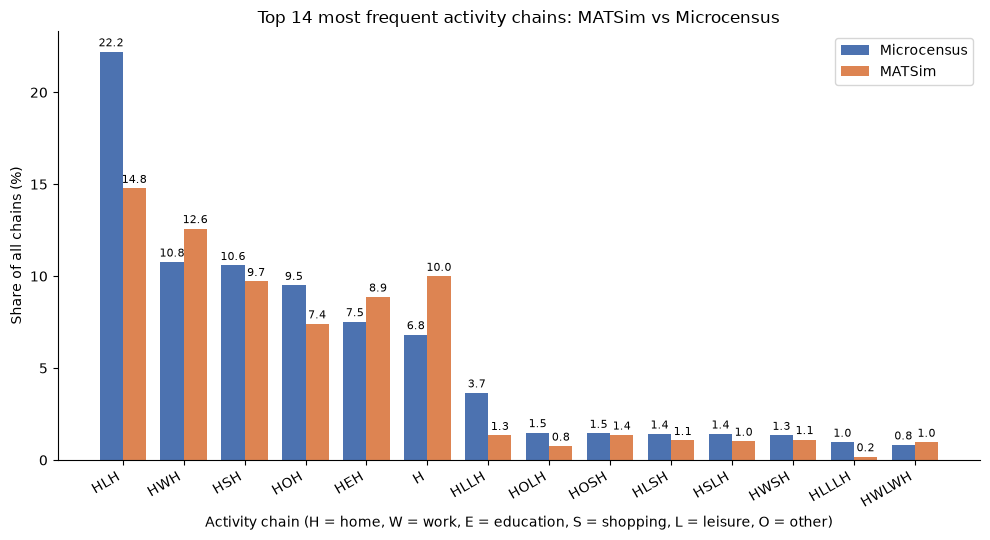

Saved chain_comparison_top14.png


In [6]:
import matplotlib.pyplot as plt
import numpy as np

def plot_top_chains(res, n=14, out="chain_comparison_top14.png"):
    top = res.head(n)                      # res is already sorted by mz_count
    x = np.arange(len(top))
    w = 0.38

    fig, ax = plt.subplots(figsize=(10, 5.5))
    b1 = ax.bar(x - w/2, top["mz_share_%"], w, label="Microcensus", color="#4C72B0")
    b2 = ax.bar(x + w/2, top["matsim_share_%"], w, label="MATSim", color="#DD8452")

    ax.bar_label(b1, fmt="%.1f", padding=2, fontsize=8)
    ax.bar_label(b2, fmt="%.1f", padding=2, fontsize=8)

    ax.set_xticks(x)
    ax.set_xticklabels(top.index, rotation=30, ha="right")
    ax.set_xlabel("Activity chain (H = home, W = work, E = education, S = shopping, L = leisure, O = other)")
    ax.set_ylabel("Share of all chains (%)")
    ax.set_title(f"Top {n} most frequent activity chains: MATSim vs Microcensus")
    ax.legend()
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    fig.savefig(out, dpi=200)
    plt.show()
    print("Saved", out)

plot_top_chains(res, n=14)